<a href="https://colab.research.google.com/github/i114180104-debug/Machine-learning/blob/main/Decision_Tree_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree Regression — Theory, Mathematics, and Code

Same treatment as the SVR notebook: every idea three times — in words, in mathematics, and as a
picture you can manipulate. Chapter 6 territory in Géron, but taken down to the derivations.

### Why this method is worth understanding properly

A regression tree is the simplest model that is genuinely **nonlinear, non-parametric, and
interpretable at the same time**. It is also the atom from which random forests, gradient boosting,
XGBoost and LightGBM are built — so every idea here is load-bearing for the ensembles that dominate
tabular prediction.

### Road map

| § | Concept | Key result |
|---|---------|-----------|
| 1 | Piecewise-constant regression | the model is a step function on boxes |
| 2 | **The optimal leaf value** | mean under squared loss, median under absolute loss (derived) |
| 3 | Why the tree is grown greedily | optimal tree construction is NP-hard |
| 4 | **The split criterion** | gain $= \frac{n_Ln_R}{n}(\bar y_L-\bar y_R)^2$ — derived exactly |
| 5 | Finding the best split in $O(n\log n)$ | prefix sums; the gain landscape |
| 6 | **A tree written from scratch** | matches scikit-learn to machine precision |
| 7 | The criterion menu | squared_error, friedman_mse, absolute_error, poisson |
| 8 | The prediction surface | 1-D steps, 2-D boxes |
| 9 | Overfitting and the stopping rules | depth, leaf size, impurity decrease |
| 10 | **Cost-complexity pruning** | $R_\alpha(T)=R(T)+\alpha|\tilde T|$, with $\alpha_{\text{eff}}$ derived |
| 11 | Three structural weaknesses | instability, axis-alignment, no extrapolation |
| 12 | Feature importance | MDI and its cardinality bias; permutation as the fix |
| 13 | Why one tree becomes a forest | the variance-of-an-average formula |
| 14 | Cheat sheet | misconceptions, defaults, references |

In [1]:
# ----------------------------------------------------------------------
# Setup
# ----------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})

C_DATA, C_FIT, C_SPLIT = "#444444", "#0072B2", "#D55E00"
C_ALT, C_OK, C_WARN     = "#CC79A7", "#009E73", "#E69F00"

try:
    from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, Checkbox
    HAS_WIDGETS = True
except Exception:
    HAS_WIDGETS = False
    print("ipywidgets unavailable -- interactive cells render one static view.")

def show(func, **controls):
    """interact(...) when widgets exist, else call func at the slider defaults."""
    if HAS_WIDGETS:
        return interact(func, **controls)
    return func(**{k: (v.value if hasattr(v, "value") else v) for k, v in controls.items()})

def make_wave(n=120, noise=0.25, seed=0, outliers=0):
    rng = np.random.default_rng(seed)
    X = np.sort(rng.uniform(-3, 3, n)).reshape(-1, 1)
    y = np.sin(X).ravel() + 0.3 * X.ravel() + noise * rng.standard_normal(n)
    if outliers:
        idx = rng.choice(n, outliers, replace=False)
        y[idx] += rng.choice([-1, 1], outliers) * rng.uniform(2.0, 3.0, outliers)
    return X, y

X, y = make_wave()
X_grid = np.linspace(-3.4, 3.4, 600).reshape(-1, 1)
print("data:", X.shape, "| widgets:", HAS_WIDGETS)

data: (120, 1) | widgets: True


---
## 1. What a regression tree *is*

Linear regression assumes a global formula. A tree assumes almost nothing. It carves the feature
space into **axis-aligned boxes** and predicts a single constant inside each box:

$$
f(x) \;=\; \sum_{m=1}^{M} c_m \,\mathbb{1}\{x \in R_m\}
$$

where $R_1,\dots,R_M$ are disjoint rectangles covering the space and $c_m$ is the constant for box
$m$. That is the entire model class: **a step function on boxes**. All the intelligence is in
choosing the boxes.

Two consequences follow immediately and are worth stating before any mathematics:

* The fit is **discontinuous** — it jumps at box boundaries. A tree will never give you a smooth
  curve, no matter how deep it is. It approximates smoothness with many small steps.
* The model is **invariant to any monotone transformation of a feature**. Replace $x$ by $\log x$ or
  $x^3$ and the tree is unchanged, because only the *ordering* of values determines the splits. This
  is why trees need no feature scaling at all — a sharp contrast with SVR, where scaling was part of
  the model definition.

In [2]:
def plot_steps(max_depth=3):
    """The model class: a step function whose resolution is set by depth."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    ax = axes[0]
    t = DecisionTreeRegressor(max_depth=max_depth, random_state=0).fit(X, y)
    yg = t.predict(X_grid)
    ax.scatter(X, y, s=20, c=C_DATA, alpha=0.7, label="data", zorder=3)
    ax.plot(X_grid, yg, color=C_FIT, lw=2.2, label=f"tree, depth {max_depth}")
    for thr in t.tree_.threshold[t.tree_.feature >= 0]:
        ax.axvline(thr, color=C_SPLIT, lw=0.8, ls="--", alpha=0.6)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"{t.get_n_leaves()} leaves -> {t.get_n_leaves()} constant pieces "
                 f"({(t.tree_.feature >= 0).sum()} split lines)")
    ax.legend(loc="upper left", fontsize=9)

    ax = axes[1]
    for d, col, lw in [(1, "#cfe3f3", 1.6), (2, "#94c4e3", 1.8),
                       (3, "#4a9bd1", 2.0), (6, C_FIT, 2.2)]:
        ax.plot(X_grid, DecisionTreeRegressor(max_depth=d, random_state=0).fit(X, y).predict(X_grid),
                color=col, lw=lw, label=f"depth {d}")
    ax.scatter(X, y, s=14, c=C_DATA, alpha=0.45, zorder=0)
    ax.set_xlabel("x"); ax.set_title("Deeper = finer steps, never smoother")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()

show(plot_steps, max_depth=IntSlider(value=3, min=1, max=10, description="max_depth")
     if HAS_WIDGETS else 3)

interactive(children=(IntSlider(value=3, description='max_depth', max=10, min=1), Output()), _dom_classes=('wi…

<function __main__.plot_steps(max_depth=3)>

---
## 2. Given the boxes, what constant should a leaf predict?

This part has an exact answer, and deriving it tells you why the default criterion is what it is.

Fix a region $R_m$ containing the points $\{y_i : x_i \in R_m\}$, with $n_m$ of them. Choose the
constant $c$ that minimises the **squared** loss inside the region:

$$
c^{*} = \arg\min_{c}\; \sum_{x_i \in R_m}(y_i - c)^2 .
$$

Differentiate and set to zero:

$$
\frac{d}{dc}\sum_i (y_i-c)^2 = -2\sum_i (y_i - c) = 0
\quad\Longrightarrow\quad
\boxed{\;c^{*} = \frac{1}{n_m}\sum_{x_i\in R_m} y_i = \bar y_m\;}
$$

**The optimal leaf value is the mean of the training targets in that leaf.** Not a convention — a
consequence of choosing squared loss.

Change the loss and the answer changes with it. Under **absolute** loss the objective
$\sum_i|y_i-c|$ has subgradient $-\sum_i \operatorname{sign}(y_i - c)$, which vanishes when as many
points lie above $c$ as below:

$$
\boxed{\;c^{*} = \operatorname{median}\{y_i : x_i \in R_m\}\;}
$$

That single difference is the whole story of `criterion="absolute_error"`: it makes every leaf a
median, which is robust to outliers but costs more to compute (no running-sum trick — §5) and is
noticeably slower.

In [3]:
def plot_leaf_constant(n_out=3):
    """Mean vs median as the leaf value, with and without contaminated points."""
    rng = np.random.default_rng(3)
    vals = np.concatenate([rng.normal(2.0, 0.4, 25),
                           rng.normal(9.0, 0.3, n_out) if n_out else np.array([])])
    cs = np.linspace(0, 11, 400)
    l2 = [(np.sum((vals - c)**2)) / len(vals) for c in cs]
    l1 = [(np.sum(np.abs(vals - c))) / len(vals) for c in cs]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
    ax = axes[0]
    ax.plot(cs, l2, lw=2.2, color=C_FIT, label="squared loss")
    ax.axvline(vals.mean(), color=C_FIT, ls="--", lw=1.6, label=f"mean = {vals.mean():.2f}")
    ax.plot(cs, l1, lw=2.2, color=C_ALT, label="absolute loss")
    ax.axvline(np.median(vals), color=C_ALT, ls=":", lw=1.8, label=f"median = {np.median(vals):.2f}")
    ax.set_xlabel("candidate leaf value c"); ax.set_ylabel("average loss in the leaf")
    ax.set_title(f"The minimiser IS the mean / median ({n_out} outliers present)")
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.eventplot(vals, orientation="horizontal", colors=C_DATA, lineoffsets=0, linelengths=0.6)
    ax.axvline(vals.mean(), color=C_FIT, lw=2, label="mean (squared loss)")
    ax.axvline(np.median(vals), color=C_ALT, lw=2, ls="--", label="median (absolute loss)")
    ax.set_yticks([]); ax.set_xlabel("y values inside one leaf")
    ax.set_title("A few contaminated points drag the mean, not the median")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()

show(plot_leaf_constant, n_out=IntSlider(value=3, min=0, max=8, description="outliers")
     if HAS_WIDGETS else 3)

interactive(children=(IntSlider(value=3, description='outliers', max=8), Output()), _dom_classes=('widget-inte…

<function __main__.plot_leaf_constant(n_out=3)>

---
## 3. Choosing the boxes: why the algorithm is greedy

With the leaf values settled, only the partition remains. The honest objective is to choose
$R_1,\dots,R_M$ *jointly* to minimise total squared error. Nobody does this, for a hard reason:

> Constructing an optimal binary decision tree is **NP-complete** (Hyafil & Rivest, 1976).

The number of possible axis-aligned partitions explodes combinatorially, so CART (Breiman, Friedman,
Olshen & Stone, 1984) settles for **recursive binary splitting** — a greedy procedure:

1. Consider every feature $j$ and every candidate threshold $s$.
2. Pick the pair $(j,s)$ that most reduces the error *right now*.
3. Split the node into $\{x : x_j \le s\}$ and $\{x : x_j > s\}$.
4. Recurse into each child until a stopping rule fires.

Greedy means **myopic**: a split that looks mediocre now may be the only route to an excellent pair
of splits later, and CART will never find it. The classic failure is XOR-like structure, where no
single axis-aligned cut improves anything but two cuts together separate the data perfectly. This is
one honest reason ensembles exist — randomised trees explore different greedy paths.

Modern optimal-tree solvers (MIP-based, e.g. `pystreed`, OCT) can find provably optimal shallow
trees for small problems, but CART's greedy recursion remains the default everywhere.

---
## 4. The split criterion, derived exactly

Here is the mathematical heart of the method, and it has a surprisingly clean closed form.

Write the node's **impurity** as its mean squared deviation from its own mean:

$$
H(Q) = \frac{1}{n_Q}\sum_{i \in Q} (y_i - \bar y_Q)^2 \qquad\text{(this is just the variance of } y \text{ in } Q)
$$

A candidate split $\theta=(j,s)$ partitions $Q$ into $Q_L$ and $Q_R$ with $n_L$ and $n_R$ points.
The quantity CART maximises is the **weighted impurity decrease**:

$$
G(Q,\theta) \;=\; H(Q)\;-\;\frac{n_L}{n}H(Q_L)\;-\;\frac{n_R}{n}H(Q_R).
$$

Now the algebra. Multiply through by $n$ to work in sums of squares, and use the classic
decomposition of total sum of squares into within and between parts:

$$
\underbrace{\sum_{i\in Q}(y_i-\bar y_Q)^2}_{SS_{\text{total}}}
=
\underbrace{\sum_{i\in Q_L}(y_i-\bar y_L)^2+\sum_{i\in Q_R}(y_i-\bar y_R)^2}_{SS_{\text{within}}}
\;+\;
\underbrace{n_L(\bar y_L-\bar y_Q)^2+n_R(\bar y_R-\bar y_Q)^2}_{SS_{\text{between}}}
$$

Substituting $\bar y_Q = (n_L\bar y_L + n_R\bar y_R)/n$ into the between-group term and simplifying
collapses it to a single product:

$$
SS_{\text{between}} = \frac{n_L n_R}{n}\left(\bar y_L - \bar y_R\right)^2
$$

Since the reduction in total squared error *is* $SS_{\text{between}}$, we get the result worth
memorising:

$$
\boxed{\;
n\,G(Q,\theta) \;=\; SS_{\text{total}} - SS_{\text{within}} \;=\; \frac{n_L n_R}{n}\bigl(\bar y_L-\bar y_R\bigr)^2
\;}
$$

**Read what this says.** The value of a split is the product of two things, and it needs *both*:

* $(\bar y_L - \bar y_R)^2$ — how differently the two sides behave. A split that separates nothing
  gains nothing, however balanced.
* $n_L n_R$ — how **balanced** the split is. This term is maximised at $n_L = n_R = n/2$ and goes to
  zero as either side empties. Peeling off a single extreme point gains almost nothing even if that
  point is wildly different.

So a regression tree is not hunting for outliers; it is hunting for **a place where a large group
behaves differently from another large group**. The next cell plots both factors and their product
across every candidate threshold, which makes the trade-off visible.

In [4]:
def plot_gain_landscape(feature=0, min_leaf=5):
    """Every candidate threshold scored by the exact gain identity of section 4."""
    xs_all = X[:, feature]
    o = np.argsort(xs_all, kind="mergesort")
    xs, ys = xs_all[o], y[o]
    n = len(ys)
    cs = np.cumsum(ys); tot = cs[-1]
    k = np.arange(n - 1)
    nL = k + 1.0; nR = n - nL
    mL = cs[:-1] / nL; mR = (tot - cs[:-1]) / nR
    gain = (nL * nR / n) * (mL - mR) ** 2
    valid = (xs[:-1] < xs[1:]) & (nL >= min_leaf) & (nR >= min_leaf)
    thr = (xs[:-1] + xs[1:]) / 2.0
    k_best = np.where(valid)[0][np.argmax(gain[valid])]

    sk = DecisionTreeRegressor(max_depth=1, min_samples_leaf=min_leaf, random_state=0).fit(X, y)
    sk_thr = sk.tree_.threshold[0]

    fig, axes = plt.subplots(3, 1, figsize=(9.5, 8.0), sharex=True,
                             gridspec_kw={"height_ratios": [1.5, 1, 1]})
    ax = axes[0]
    ax.scatter(xs, ys, s=18, c=C_DATA, alpha=0.7)
    ax.axvline(thr[k_best], color=C_SPLIT, lw=2)
    ax.hlines(mL[k_best], xs.min(), thr[k_best], color=C_FIT, lw=2.4)
    ax.hlines(mR[k_best], thr[k_best], xs.max(), color=C_FIT, lw=2.4)
    ax.set_ylabel("y"); ax.set_title(f"Best split at x = {thr[k_best]:.3f}   "
                                     f"(sklearn chose {sk_thr:.3f})")

    ax = axes[1]
    ax.plot(thr[valid], ((mL - mR) ** 2)[valid], color=C_ALT, lw=2, label=r"separation $(\bar y_L-\bar y_R)^2$")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(thr[valid], (nL * nR / n)[valid], color=C_WARN, lw=2, label=r"balance $n_Ln_R/n$")
    ax.set_ylabel("separation", color=C_ALT); ax2.set_ylabel("balance", color=C_WARN)
    ax.set_title("The two factors pull in different directions", fontsize=10)

    ax = axes[2]
    ax.plot(thr[valid], gain[valid], color=C_FIT, lw=2.2)
    ax.axvline(thr[k_best], color=C_SPLIT, lw=2, label="argmax")
    ax.set_xlabel(f"candidate threshold on feature {feature}")
    ax.set_ylabel("gain"); ax.set_title(r"their product: gain $= \frac{n_Ln_R}{n}(\bar y_L-\bar y_R)^2$",
                                        fontsize=10)
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    gap = abs(thr[k_best] - sk_thr)
    print(f"gain at the chosen split: {gain[k_best]:.4f}")
    print(f"my threshold {thr[k_best]:.9f} vs sklearn {sk_thr:.9f}  (difference {gap:.1e})")
    print("They agree to float32 precision, not float64: sklearn casts X to float32 internally, "
          "so its midpoint is computed in single precision. Same split, different last digits.")

show(plot_gain_landscape,
     min_leaf=IntSlider(value=5, min=1, max=30, description="min_samples_leaf") if HAS_WIDGETS else 5)

interactive(children=(IntSlider(value=0, description='feature', max=1), IntSlider(value=5, description='min_sa…

<function __main__.plot_gain_landscape(feature=0, min_leaf=5)>

---
## 5. Finding the best split efficiently

A naive implementation recomputes both group means for every candidate threshold: $O(n)$ work per
candidate, $O(n^2)$ per feature. The standard trick removes a whole factor of $n$.

**Sort the node's points by the feature once.** Then sweep the split position from left to right,
maintaining running (prefix) sums. If $S_k=\sum_{i\le k} y_i$ is the prefix sum after sorting and
$S$ is the node total, then for a split after position $k$:

$$
n_L = k+1,\qquad n_R = n-n_L,\qquad
\bar y_L = \frac{S_k}{n_L},\qquad
\bar y_R = \frac{S-S_k}{n_R}
$$

and the gain follows from §4 in **constant time** per candidate. Total cost per feature:
$O(n\log n)$ for the sort, $O(n)$ for the sweep. With $d$ features and a balanced tree of depth
$D$, the overall cost is roughly

$$
O\bigl(d\,n\log n \cdot D\bigr)
$$

which is why trees train in milliseconds where kernel methods take seconds.

Two practical notes. The threshold is placed **midway between consecutive distinct values**, not on a
data point, so the boundary sits in the gap. And candidates where the two neighbouring feature values
are *equal* must be skipped — you cannot split between identical values.

**Why `absolute_error` is slow:** the median has no prefix-sum update. Maintaining it as the split
sweeps requires an order statistic structure, and scikit-learn's implementation is substantially
more expensive — often 10× or worse. Use it when you need robustness, not by default.

---
## 6. The whole algorithm, from scratch

Below is CART regression in about forty lines: the sorted sweep of §5, the gain identity of §4, the
leaf mean of §2, and the recursion of §3. Then it is checked against `DecisionTreeRegressor` — if
the derivation is right, the two must agree **exactly**, not approximately, because both are solving
the same deterministic greedy problem.

In [5]:
def best_split(X, y, min_samples_leaf=1):
    """Exhaustive search over (feature, threshold) using the section-4 gain identity.

    Returns (gain, feature_index, threshold). O(n log n) per feature via sorted prefix sums.
    """
    n, d = X.shape
    best = (0.0, None, None)
    for j in range(d):
        order = np.argsort(X[:, j], kind="mergesort")       # stable sort = reproducible ties
        xs, ys = X[order, j], y[order]
        csum = np.cumsum(ys); total = csum[-1]
        k = np.arange(n - 1)
        nL = k + 1.0
        nR = n - nL
        mean_L = csum[:-1] / nL
        mean_R = (total - csum[:-1]) / nR
        gain = (nL * nR / n) * (mean_L - mean_R) ** 2        # <-- the identity, vectorised
        ok = (xs[:-1] < xs[1:]) & (nL >= min_samples_leaf) & (nR >= min_samples_leaf)
        if not ok.any():
            continue
        gi = np.where(ok)[0][np.argmax(gain[ok])]
        if gain[gi] > best[0] + 1e-12:
            best = (float(gain[gi]), j, float((xs[gi] + xs[gi + 1]) / 2.0))
    return best

def grow_tree(X, y, depth=0, max_depth=3, min_samples_split=2, min_samples_leaf=1,
              min_impurity_decrease=0.0, n_total=None):
    """Recursive binary splitting. Leaf value = mean of y (section 2)."""
    n_total = len(y) if n_total is None else n_total
    node = {"value": float(y.mean()), "n": int(len(y)),
            "impurity": float(np.mean((y - y.mean()) ** 2))}
    if (depth >= max_depth or len(y) < min_samples_split or np.ptp(y) == 0):
        return node
    gain, j, thr = best_split(X, y, min_samples_leaf)
    if j is None:
        return node
    # sklearn compares the decrease weighted by this node's share of all samples
    if (len(y) / n_total) * (gain / len(y)) < min_impurity_decrease:
        return node
    mask = X[:, j] <= thr
    node.update(feature=j, threshold=thr, gain=float(gain),
                left=grow_tree(X[mask], y[mask], depth + 1, max_depth, min_samples_split,
                               min_samples_leaf, min_impurity_decrease, n_total),
                right=grow_tree(X[~mask], y[~mask], depth + 1, max_depth, min_samples_split,
                                min_samples_leaf, min_impurity_decrease, n_total))
    return node

def tree_predict(node, X):
    out = np.empty(len(X))
    for i, row in enumerate(X):
        nd = node
        while "feature" in nd:                                # walk down to a leaf
            nd = nd["left"] if row[nd["feature"]] <= nd["threshold"] else nd["right"]
        out[i] = nd["value"]
    return out

def count_leaves(node):
    return 1 if "feature" not in node else count_leaves(node["left"]) + count_leaves(node["right"])

# ---- verification against scikit-learn on several shapes and depths ----
rng = np.random.default_rng(0)
print(f"{'n':>5} {'d':>3} {'depth':>6} {'leaves(mine)':>13} {'leaves(sk)':>11} {'max|Δpred|':>12}")
for n, d in [(200, 1), (300, 4), (500, 8)]:
    Xv = rng.uniform(-3, 3, (n, d))
    yv = np.sin(Xv[:, 0]) + (0.5 * Xv[:, 1] if d > 1 else 0) + 0.2 * rng.standard_normal(n)
    for md_ in (2, 3, 5):
        mine = grow_tree(Xv, yv, max_depth=md_, min_samples_leaf=5, min_samples_split=10)
        sk = DecisionTreeRegressor(max_depth=md_, min_samples_leaf=5, min_samples_split=10,
                                   random_state=0).fit(Xv, yv)
        diff = np.abs(tree_predict(mine, Xv) - sk.predict(Xv)).max()
        print(f"{n:>5} {d:>3} {md_:>6} {count_leaves(mine):>13} {sk.get_n_leaves():>11} {diff:>12.2e}")
print("\nAgreement at machine precision: the gain identity of section 4 reproduces libsklearn's "
      "split choices exactly, leaf for leaf.")

    n   d  depth  leaves(mine)  leaves(sk)   max|Δpred|
  200   1      2             4           4     3.33e-16
  200   1      3             8           8     3.33e-16
  200   1      5            20          20     1.11e-16
  300   4      2             4           4     2.22e-16
  300   4      3             8           8     3.33e-16
  300   4      5            29          29     4.44e-16
  500   8      2             4           4     1.33e-15
  500   8      3             8           8     8.88e-16
  500   8      5            31          31     8.88e-16

Agreement at machine precision: the gain identity of section 4 reproduces libsklearn's split choices exactly, leaf for leaf.


---
## 7. The criterion menu

scikit-learn offers four criteria for regression. Knowing what each one optimises tells you when to
reach for it.

| `criterion` | Leaf value | Impurity minimised | Use when |
|---|---|---|---|
| `squared_error` (default) | mean | variance | the default; fastest; assumes symmetric noise |
| `friedman_mse` | mean | same splits, different *node* scoring | boosting; best-first growth |
| `absolute_error` | **median** | mean absolute deviation | heavy-tailed noise, outliers; much slower |
| `poisson` | mean | Poisson deviance | non-negative **count** targets |

**`friedman_mse` deserves a precise statement**, because it is widely misunderstood. Friedman's
improvement score is

$$
i^2 = \frac{n_L n_R}{n_L+n_R}\left(\bar y_L - \bar y_R\right)^2
$$

Compare with §4: the squared-error gain is the same product divided by $n$. Within a single node $n$
is fixed, so **the two criteria rank candidate splits identically and pick the same split** — that is
a theorem, not a coincidence, and the cell below confirms it on 25 random datasets.

Where they *could* diverge is when nodes compete with each other, as under best-first growth
(`max_leaf_nodes`), because `friedman_mse` does not divide by the node size and so scores large nodes
more generously. In practice this is hard to observe: the same test with `max_leaf_nodes=6` found
**no** difference on 25 datasets. Treat the two as interchangeable for regression, and reach for
`friedman_mse` only because gradient boosting uses it by default.

**`poisson` matters for your domain.** For count-like targets (organism counts, exceedance counts)
the deviance

$$
H(Q) = \frac{2}{n_Q}\sum_{i\in Q}\left(y_i\log\frac{y_i}{\bar y_Q} - y_i + \bar y_Q\right)
$$

respects the mean–variance relationship of count data, which squared error does not. It requires
strictly non-negative $y$.

depth-limited growth: identical predictions in 25/25 random datasets
best-first growth (max_leaf_nodes=6): they differ in 0/25 datasets  -- in principle they can diverge here, but empirically they rarely do


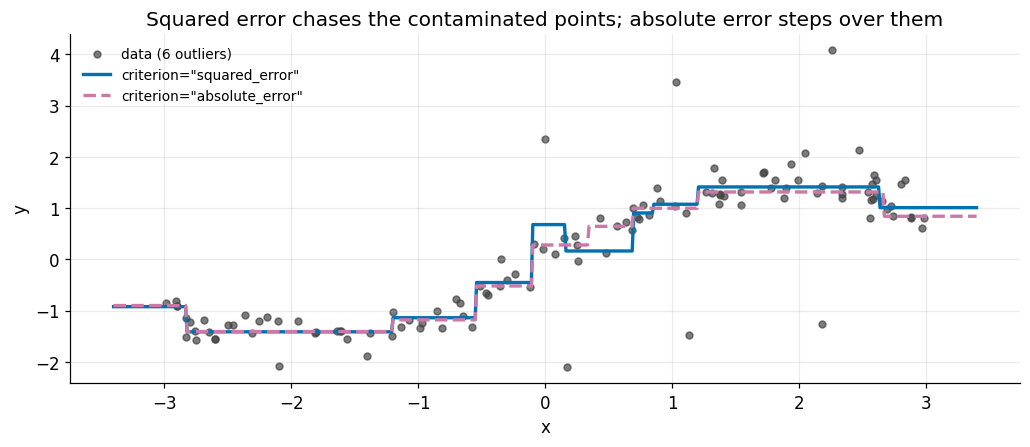

In [6]:
# Do squared_error and friedman_mse really choose the same splits? (section 7 claim)
rng = np.random.default_rng(7)
agree = []
for trial in range(25):
    Xv = rng.uniform(-3, 3, (200, 3))
    yv = np.sin(Xv[:, 0]) + 0.4 * Xv[:, 2] + 0.3 * rng.standard_normal(200)
    a = DecisionTreeRegressor(criterion="squared_error", max_depth=3, random_state=0).fit(Xv, yv)
    b = DecisionTreeRegressor(criterion="friedman_mse",  max_depth=3, random_state=0).fit(Xv, yv)
    agree.append(np.allclose(a.predict(Xv), b.predict(Xv)))
print(f"depth-limited growth: identical predictions in {sum(agree)}/{len(agree)} random datasets")

# ... and where they diverge: best-first growth, where nodes compete for the next split
diff_count = 0
for trial in range(25):
    Xv = rng.uniform(-3, 3, (200, 3))
    yv = np.sin(Xv[:, 0]) + 0.4 * Xv[:, 2] + 0.3 * rng.standard_normal(200)
    a = DecisionTreeRegressor(criterion="squared_error", max_leaf_nodes=6, random_state=0).fit(Xv, yv)
    b = DecisionTreeRegressor(criterion="friedman_mse",  max_leaf_nodes=6, random_state=0).fit(Xv, yv)
    diff_count += (not np.allclose(a.predict(Xv), b.predict(Xv)))
print(f"best-first growth (max_leaf_nodes=6): they differ in {diff_count}/25 datasets"
      f"  -- in principle they can diverge here, but empirically they rarely do")

# the robustness difference that absolute_error buys
Xo, yo = make_wave(n=120, noise=0.25, seed=0, outliers=6)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.scatter(Xo, yo, s=20, c=C_DATA, alpha=0.7, label="data (6 outliers)")
for crit, col, ls in [("squared_error", C_FIT, "-"), ("absolute_error", C_ALT, "--")]:
    t = DecisionTreeRegressor(criterion=crit, max_depth=4, min_samples_leaf=5, random_state=0).fit(Xo, yo)
    ax.plot(X_grid, t.predict(X_grid), color=col, lw=2.2, ls=ls, label=f'criterion="{crit}"')
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=9)
ax.set_title("Squared error chases the contaminated points; absolute error steps over them")
fig.tight_layout(); plt.show()

---
## 8. The prediction surface in two dimensions

In 1-D a tree is a staircase. In 2-D it is a **patchwork of rectangles**, and seeing it is the
fastest way to understand both the power and the limitation of axis-aligned splitting.

Each internal node draws one line perpendicular to an axis, *within the region its parent handed it*.
That nesting is why the partition is a hierarchy of boxes rather than a grid: a split only affects
the sub-region below it.

In [7]:
def plot_2d_partition(max_depth=3, n=300, seed=1):
    """Boxes, not curves: the geometry of axis-aligned recursive splitting."""
    rng = np.random.default_rng(seed)
    X2 = rng.uniform(-3, 3, (n, 2))
    y2 = np.sin(X2[:, 0]) * np.cos(X2[:, 1]) + 0.15 * rng.standard_normal(n)
    t = DecisionTreeRegressor(max_depth=max_depth, random_state=0).fit(X2, y2)

    gx, gy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
    Z = t.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
    ax = axes[0]
    im = ax.pcolormesh(gx, gy, Z, cmap="RdBu_r", shading="auto")
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="RdBu_r", s=14, edgecolors="k", linewidths=0.3)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(False)
    ax.set_title(f"Prediction surface, depth {max_depth} ({t.get_n_leaves()} boxes)")
    fig.colorbar(im, ax=ax, label="prediction")

    # draw the recursive partition by walking the tree with its bounding box
    ax = axes[1]
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="RdBu_r", s=14, edgecolors="k", linewidths=0.3)
    T = t.tree_
    def draw(node, x0, x1, y0, y1, depth):
        if T.feature[node] == -2:
            ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="#222222", lw=0.6))
            return
        f, thr = T.feature[node], T.threshold[node]
        if f == 0:
            ax.plot([thr, thr], [y0, y1], color=C_SPLIT, lw=max(0.8, 2.4 - 0.4*depth))
            draw(T.children_left[node], x0, thr, y0, y1, depth+1)
            draw(T.children_right[node], thr, x1, y0, y1, depth+1)
        else:
            ax.plot([x0, x1], [thr, thr], color=C_SPLIT, lw=max(0.8, 2.4 - 0.4*depth))
            draw(T.children_left[node], x0, x1, y0, thr, depth+1)
            draw(T.children_right[node], x0, x1, thr, y1, depth+1)
    draw(0, -3, 3, -3, 3, 0)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.grid(False)
    ax.set_xlabel("$x_1$"); ax.set_title("The recursive partition (thick = early split)")
    fig.tight_layout(); plt.show()

show(plot_2d_partition, max_depth=IntSlider(value=3, min=1, max=8, description="max_depth")
     if HAS_WIDGETS else 3)

interactive(children=(IntSlider(value=3, description='max_depth', max=8, min=1), IntSlider(value=300, descript…

<function __main__.plot_2d_partition(max_depth=3, n=300, seed=1)>

---
## 9. Overfitting, and the five knobs that prevent it

A tree grown without limits will keep splitting until every leaf is pure — in regression, until
every leaf holds a single point (or identical points). That tree has **zero training error and no
generalisation**: it has memorised the sample, noise included.

Unlike SVR, where regularisation enters the objective as $\tfrac12\lVert w\rVert^2$, a tree is
regularised **structurally** — by refusing to grow. Five knobs, with their geometric meaning:

| Parameter | Mechanism | Geometric meaning |
|---|---|---|
| `max_depth` | hard cap on splits from root to leaf | at most $2^{D}$ boxes |
| `min_samples_leaf` | every leaf needs $\ge k$ points | no box may be nearly empty — **the most directly useful knob** |
| `min_samples_split` | a node needs $\ge k$ points to split at all | stops subdividing small regions |
| `min_impurity_decrease` | a split must earn at least $\delta$ | rejects splits that barely help (§4's gain, weighted by node share) |
| `max_leaf_nodes` | total box budget, grown best-first | spends depth where it pays |

`min_samples_leaf` is the one to reach for first: it directly controls how many points each averaged
prediction rests on, which is exactly the variance of that prediction. A leaf of one point predicts
one noisy observation.

The validation curve below shows the classic shape. Note where training error goes (down, always)
against test error (down, then up) — and that the gap between them *is* the overfitting.

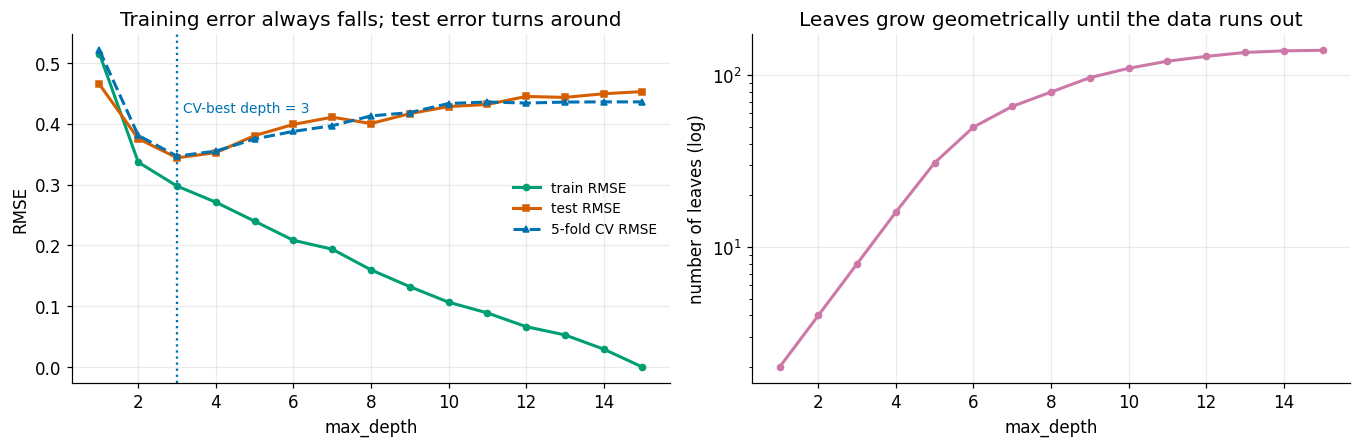

deepest tree: 140 leaves for 140 training points -> about 1.0 points per leaf


In [8]:
def plot_depth_curve(n=200, noise=0.3, seed=2):
    Xa, ya = make_wave(n=n, noise=noise, seed=seed)
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.3, random_state=0)
    depths = range(1, 16)
    tr_e, te_e, cv_e, leaves = [], [], [], []
    for d in depths:
        t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(Xtr, ytr)
        tr_e.append(np.sqrt(mean_squared_error(ytr, t.predict(Xtr))))
        te_e.append(np.sqrt(mean_squared_error(yte, t.predict(Xte))))
        cv = -cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=0), Xa, ya,
                              cv=KFold(5, shuffle=True, random_state=0),
                              scoring="neg_root_mean_squared_error")
        cv_e.append(cv.mean()); leaves.append(t.get_n_leaves())

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    ax = axes[0]
    ax.plot(depths, tr_e, "o-", color=C_OK, lw=2, ms=4, label="train RMSE")
    ax.plot(depths, te_e, "s-", color=C_SPLIT, lw=2, ms=4, label="test RMSE")
    ax.plot(depths, cv_e, "^--", color=C_FIT, lw=2, ms=4, label="5-fold CV RMSE")
    best = int(np.argmin(cv_e)) + 1
    ax.axvline(best, color=C_FIT, ls=":", lw=1.5)
    ax.text(best + 0.15, max(te_e) * 0.9, f"CV-best depth = {best}", fontsize=9, color=C_FIT)
    ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE")
    ax.set_title("Training error always falls; test error turns around")
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.plot(depths, leaves, "o-", color=C_ALT, lw=2, ms=4)
    ax.set_yscale("log"); ax.set_xlabel("max_depth"); ax.set_ylabel("number of leaves (log)")
    ax.set_title("Leaves grow geometrically until the data runs out")
    fig.tight_layout(); plt.show()
    print(f"deepest tree: {leaves[-1]} leaves for {len(Xtr)} training points "
          f"-> about {len(Xtr)/leaves[-1]:.1f} points per leaf")

plot_depth_curve()

---
## 10. Cost-complexity pruning: the principled way to size a tree

Tuning `max_depth` by cross-validation works, but it is a blunt instrument — depth is global, while
the right amount of detail usually varies across the tree. **Cost-complexity pruning** (CART's own
answer, also called weakest-link pruning) does something smarter: grow the tree fully, then remove
the sub-trees that buy the least accuracy per leaf.

Define, for a tree $T$ with leaf set $\tilde T$:

$$
R_\alpha(T) \;=\; \underbrace{R(T)}_{\text{total weighted leaf impurity}} \;+\; \alpha\,|\tilde T|
$$

where $R(T)=\sum_{t\in\tilde T}\frac{n_t}{N}H(t)$ and $\alpha\ge 0$ is the price of a leaf. At
$\alpha=0$ the full tree wins; as $\alpha$ grows, leaves become too expensive and the tree collapses
toward a single node.

**The key derivation.** For an internal node $t$, compare keeping its sub-tree $T_t$ against
collapsing it to a single leaf. The sub-tree is worth keeping while
$R_\alpha(T_t) < R_\alpha(t)$, i.e. while

$$
R(T_t) + \alpha|\tilde T_t| \;<\; R(t) + \alpha
$$

Solving for the $\alpha$ at which the two are exactly equal gives that node's **effective alpha**:

$$
\boxed{\;\alpha_{\text{eff}}(t) \;=\; \frac{R(t) - R(T_t)}{|\tilde T_t| - 1}\;}
$$

This is the "price per leaf" that node's sub-tree is paying for its accuracy. The **weakest link** is
the node with the smallest $\alpha_{\text{eff}}$ — the worst value for money — and pruning it first
generates a finite, nested sequence of optimal sub-trees $T_0 \supset T_1 \supset \dots \supset
\{\text{root}\}$ with a matching increasing sequence of $\alpha$ values. That sequence is exactly
what `cost_complexity_pruning_path` returns, and the next cell verifies the formula against it.

You then choose $\alpha$ **by cross-validation** — one scalar, with a guarantee that for each $\alpha$
you have the best sub-tree of that complexity. This is strictly better than guessing a depth.

weakest-link alpha_eff computed by hand : 7.341860e-07
first positive alpha from sklearn       : 7.341860e-07
formula verified: True



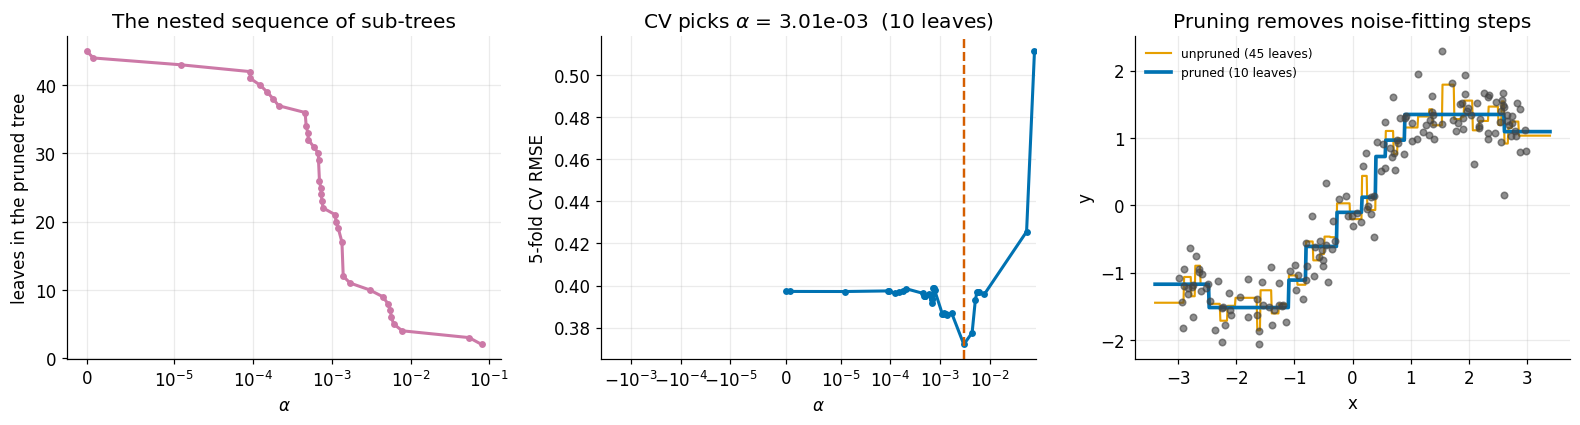

In [9]:
def ccp_demo(n=160, noise=0.3, seed=0):
    Xa, ya = make_wave(n=n, noise=noise, seed=seed)
    full = DecisionTreeRegressor(max_depth=None, min_samples_leaf=3, random_state=0).fit(Xa, ya)

    # --- verify the alpha_eff formula of section 10 against sklearn's own path ---
    T = full.tree_; N = T.n_node_samples[0]
    R = T.n_node_samples / N * T.impurity                      # weighted node risk
    def leaves_below(i):
        if T.feature[i] == -2: return [i]
        return leaves_below(T.children_left[i]) + leaves_below(T.children_right[i])
    my_alphas = []
    for i in range(T.node_count):
        if T.feature[i] != -2:
            lv = leaves_below(i)
            my_alphas.append((R[i] - R[lv].sum()) / (len(lv) - 1))
    path = full.cost_complexity_pruning_path(Xa, ya)
    weakest = min(my_alphas)
    sk_first = path.ccp_alphas[1] if path.ccp_alphas[0] == 0 else path.ccp_alphas[0]
    print(f"weakest-link alpha_eff computed by hand : {weakest:.6e}")
    print(f"first positive alpha from sklearn       : {sk_first:.6e}")
    print(f"formula verified: {np.isclose(weakest, sk_first, rtol=1e-9)}\n")

    # --- the full path, scored by cross-validation ---
    alphas = path.ccp_alphas[:-1]                              # drop the root-only tree
    cv_rmse, n_leaves = [], []
    for a in alphas:
        m = DecisionTreeRegressor(ccp_alpha=a, min_samples_leaf=3, random_state=0)
        cv_rmse.append(-cross_val_score(m, Xa, ya, cv=KFold(5, shuffle=True, random_state=0),
                                        scoring="neg_root_mean_squared_error").mean())
        n_leaves.append(m.fit(Xa, ya).get_n_leaves())
    best_a = alphas[int(np.argmin(cv_rmse))]
    pruned = DecisionTreeRegressor(ccp_alpha=best_a, min_samples_leaf=3, random_state=0).fit(Xa, ya)

    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))
    ax = axes[0]
    ax.plot(alphas, n_leaves, "o-", color=C_ALT, lw=2, ms=3.5)
    ax.set_xscale("symlog", linthresh=1e-5)
    ax.set_xlabel(r"$\alpha$"); ax.set_ylabel("leaves in the pruned tree")
    ax.set_title("The nested sequence of sub-trees")

    ax = axes[1]
    ax.plot(alphas, cv_rmse, "o-", color=C_FIT, lw=2, ms=3.5)
    ax.axvline(best_a, color=C_SPLIT, ls="--", lw=1.6)
    ax.set_xscale("symlog", linthresh=1e-5)
    ax.set_xlabel(r"$\alpha$"); ax.set_ylabel("5-fold CV RMSE")
    ax.set_title(f"CV picks $\\alpha$ = {best_a:.2e}  ({pruned.get_n_leaves()} leaves)")

    ax = axes[2]
    ax.scatter(Xa, ya, s=18, c=C_DATA, alpha=0.6, zorder=3)
    ax.plot(X_grid, full.predict(X_grid), color=C_WARN, lw=1.4,
            label=f"unpruned ({full.get_n_leaves()} leaves)")
    ax.plot(X_grid, pruned.predict(X_grid), color=C_FIT, lw=2.4,
            label=f"pruned ({pruned.get_n_leaves()} leaves)")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title("Pruning removes noise-fitting steps")
    fig.tight_layout(); plt.show()

ccp_demo()

---
## 11. Three structural weaknesses you cannot tune away

**(a) Instability.** The greedy choice at the root is made once, and everything below depends on it.
Change a handful of training points and a different feature may win the root split, producing a
visibly different tree. Trees are **high-variance, low-bias** estimators. The figure below refits on
bootstrap resamples: the spaghetti is the variance.

**(b) Axis-alignment.** Every boundary is perpendicular to an axis, so a diagonal relationship must
be approximated by a staircase. Rotate your features by 45° and the same data suddenly needs far
more leaves for the same accuracy. (PCA before a tree sometimes helps for this reason, at the cost of
interpretability — and this limitation is precisely what oblique trees and gradient boosting with
linear leaves try to fix.)

**(c) No extrapolation.** Outside the range of the training data, a tree returns the value of the
nearest leaf — a **constant**, forever. This is the same failure we measured for the RBF-SVR in
Part 1, arriving from completely different mathematics: the SVR's kernel decays to zero, the tree's
box extends to infinity. For a time series with a trend, both will flatline. Detrend, or difference,
before handing the target to either.

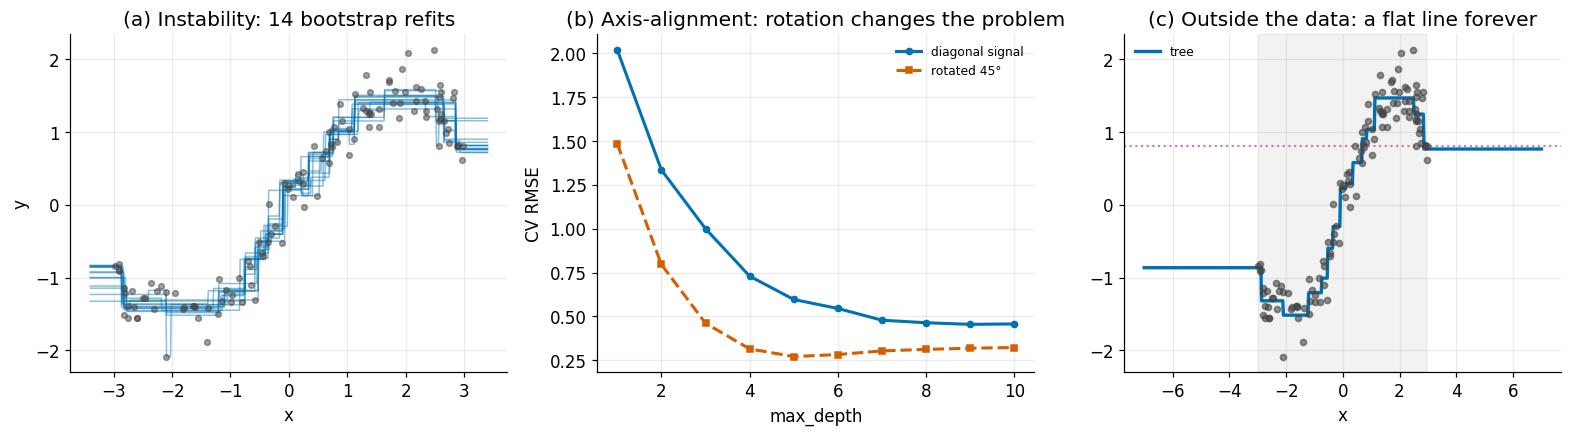

In [10]:
def plot_weaknesses(n_boot=14, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1))

    # (a) instability under resampling
    ax = axes[0]
    for b in range(n_boot):
        idx = rng.choice(len(X), len(X), replace=True)
        t = DecisionTreeRegressor(max_depth=4, min_samples_leaf=4,
                                  random_state=0).fit(X[idx], y[idx])
        ax.plot(X_grid, t.predict(X_grid), color=C_FIT, lw=1.0, alpha=0.45)
    ax.scatter(X, y, s=14, c=C_DATA, alpha=0.5, zorder=3)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"(a) Instability: {n_boot} bootstrap refits")

    # (b) axis-alignment: the same problem, rotated
    ax = axes[1]
    n = 400
    Z = rng.uniform(-3, 3, (n, 2))
    yz = (Z[:, 0] + Z[:, 1]) + 0.2 * rng.standard_normal(n)       # a perfectly diagonal signal
    th = np.pi / 4
    Rot = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    leaves_plain, leaves_rot = [], []
    depths = range(1, 11)
    for d in depths:
        leaves_plain.append(-cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=0),
                                             Z @ Rot.T, yz, cv=5,
                                             scoring="neg_root_mean_squared_error").mean())
        leaves_rot.append(-cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=0),
                                           Z, yz, cv=5,
                                           scoring="neg_root_mean_squared_error").mean())
    ax.plot(depths, leaves_rot, "o-", color=C_FIT, lw=2, ms=4, label="diagonal signal")
    ax.plot(depths, leaves_plain, "s--", color=C_SPLIT, lw=2, ms=4, label="rotated 45°")
    ax.set_xlabel("max_depth"); ax.set_ylabel("CV RMSE")
    ax.set_title("(b) Axis-alignment: rotation changes the problem")
    ax.legend(fontsize=8)

    # (c) no extrapolation
    ax = axes[2]
    wide = np.linspace(-7, 7, 600).reshape(-1, 1)
    t = DecisionTreeRegressor(max_depth=5, min_samples_leaf=4, random_state=0).fit(X, y)
    ax.axvspan(X.min(), X.max(), color="#000000", alpha=0.05)
    ax.plot(wide, t.predict(wide), color=C_FIT, lw=2.2, label="tree")
    ax.scatter(X, y, s=16, c=C_DATA, alpha=0.6, zorder=3)
    ax.axhline(y[X.ravel() == X.max()][0], color=C_ALT, ls=":", lw=1.4)
    ax.set_xlabel("x"); ax.set_title("(c) Outside the data: a flat line forever")
    ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout(); plt.show()

plot_weaknesses()

---
## 12. Feature importance: what the default number really measures

`tree.feature_importances_` reports **mean decrease in impurity** (MDI). For feature $j$:

$$
\text{MDI}(j) \;=\; \sum_{t\,:\,\text{split}(t)=j} \frac{n_t}{N}\,G(Q_t,\theta_t)
$$

— every split on that feature, weighted by the fraction of samples reaching it, summed and then
normalised to total 1. It is free, because the quantities were already computed during training.

It is also **biased**, in a way that matters:

1. **Cardinality bias.** A continuous or high-cardinality feature offers many candidate thresholds,
   so it gets more chances to look good by luck. A pure-noise continuous feature can out-rank a
   genuinely informative binary one.
2. **It is computed on training data.** It measures what the tree *used*, not what generalises.
3. **Correlated features split the credit** arbitrarily between themselves.

**Permutation importance on held-out data** fixes (1) and (2): shuffle a column, measure the drop in
test score. The demo below makes the bias unmistakable by planting **three pure-noise features that
differ only in cardinality** — continuous, ten-level, binary — alongside a single real binary signal.
A fully grown tree hands those three noise features **roughly half** of its total MDI budget, ordered
exactly by how many split points each one offers (0.34 / 0.12 / 0.05). Permutation importance on held-out data correctly gives all
three approximately zero.

Note the condition: the bias is worst in a **fully grown** tree, where deep splits on a continuous
noise feature can always shave a little training impurity. Restricting `min_samples_leaf` suppresses
much of it — try the sliders.

In [11]:
def importance_bias(n=400, seed=0, max_depth=None, min_samples_leaf=1):
    """Three pure-noise features of DIFFERENT cardinality, and one real (binary) signal."""
    rng = np.random.default_rng(seed)
    x_binary   = (rng.random(n) < 0.5).astype(float)        # the ONLY feature carrying signal
    x_noise_hi = rng.uniform(0, 1, n)                       # pure noise, ~n distinct values
    x_noise_md = rng.integers(0, 10, n).astype(float)       # pure noise, 10 distinct values
    x_noise_lo = (rng.random(n) < 0.5).astype(float)        # pure noise, 2 values
    Xf = np.c_[x_binary, x_noise_hi, x_noise_md, x_noise_lo]
    yf = 1.0 * x_binary + 0.5 * rng.standard_normal(n)
    names = ["signal (binary)", "NOISE (continuous)", "NOISE (10 levels)", "NOISE (binary)"]

    Xtr, Xte, ytr, yte = train_test_split(Xf, yf, test_size=0.3, random_state=0)
    t = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                              random_state=0).fit(Xtr, ytr)
    mdi = t.feature_importances_
    perm = permutation_importance(t, Xte, yte, n_repeats=40, random_state=0, scoring="r2")

    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    yy = np.arange(len(names))
    ax.barh(yy - 0.2, mdi, height=0.38, color=C_WARN, label="MDI (impurity, train)")
    ax.barh(yy + 0.2, perm.importances_mean, height=0.38, color=C_FIT,
            label="permutation (test)")
    ax.set_yticks(yy); ax.set_yticklabels(names); ax.axvline(0, color="#888", lw=1)
    ax.set_xlabel("importance"); ax.legend(fontsize=9)
    ax.set_title("MDI pays the noise features in order of their cardinality")
    fig.tight_layout(); plt.show()

    for nm, a, b in zip(names, mdi, perm.importances_mean):
        print(f"  {nm:22s}  MDI {a:6.3f}   permutation {b:+7.4f}")
    noise_share = mdi[1:].sum()
    print(f"\nThe three NOISE features carry {100*noise_share:.0f}% of the total MDI budget, "
          f"ranked exactly by cardinality ({mdi[1]:.3f} > {mdi[2]:.3f} > {mdi[3]:.3f}) even though "
          "none of them has any relationship with y whatsoever.")
    print("Permutation importance on held-out data gives all three approximately zero. "
          "That is the number to report.")

show(importance_bias,
     max_depth=Dropdown(options=[("fully grown", None), (10, 10), (8, 8), (6, 6), (4, 4)],
                        value=None, description="max_depth") if HAS_WIDGETS else None,
     min_samples_leaf=IntSlider(value=1, min=1, max=20, description="min_leaf") if HAS_WIDGETS else 1)

interactive(children=(IntSlider(value=400, description='n', max=1200, min=-400), IntSlider(value=0, descriptio…

<function __main__.importance_bias(n=400, seed=0, max_depth=None, min_samples_leaf=1)>

---
## 13. Why one tree becomes a forest

We now have a precise diagnosis: a deep tree has **low bias and high variance** (§11a). There is a
classical remedy for exactly that condition — average many of them.

For $B$ identically distributed estimators each with variance $\sigma^2$ and pairwise correlation
$\rho$, the variance of their average is

$$
\operatorname{Var}\!\left(\frac{1}{B}\sum_{b=1}^{B} f_b(x)\right)
= \rho\,\sigma^{2} + \frac{1-\rho}{B}\,\sigma^{2}
$$

Read the two terms. The second vanishes as $B\to\infty$ — adding trees always helps, with
diminishing returns. The first does **not**: it is floored by how correlated the trees are. This
single formula explains the whole design of modern tree ensembles:

* **Bagging** decorrelates by resampling the training data — $\rho$ falls somewhat.
* **Random forests** additionally sample a random subset of features at each split (`max_features`),
  attacking $\rho$ directly. That is the entire difference from bagging, and it is why
  `max_features` is a forest's most important hyper-parameter.
* **Extremely randomised trees** also randomise the thresholds, pushing $\rho$ lower still at some
  cost in individual tree quality.
* **Boosting** takes the opposite route: build *shallow, high-bias* trees sequentially, each fitting
  the previous residuals, reducing bias instead of variance.

The cell below measures the first term empirically — test error against $B$, flattening onto a floor
that a single tree never reaches.

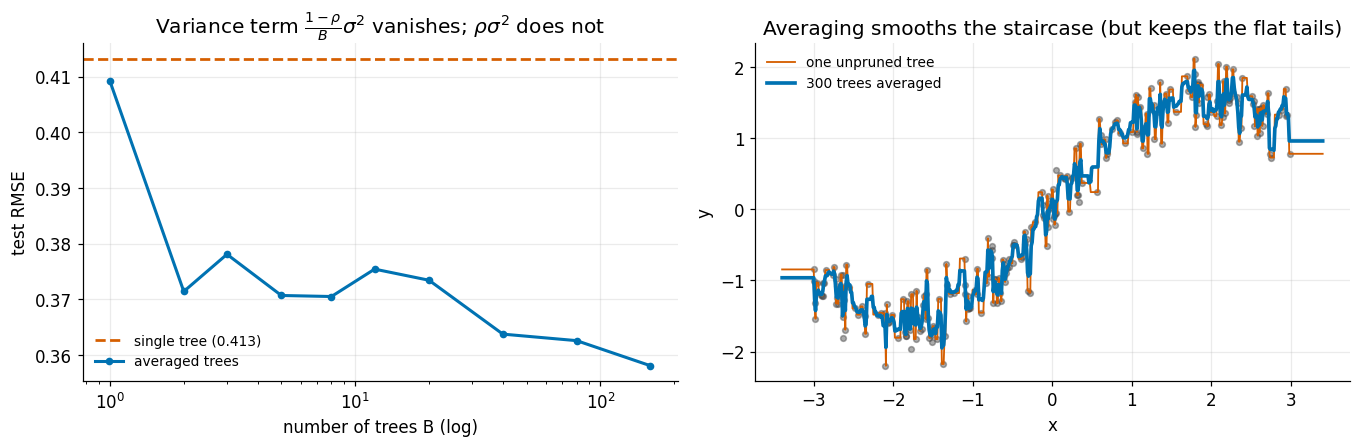

single tree 0.413 -> 160 trees 0.358  (13% lower RMSE, from variance reduction alone)


In [12]:
def averaging_demo(seed=0):
    Xa, ya = make_wave(n=250, noise=0.3, seed=5)
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.35, random_state=0)
    Bs = [1, 2, 3, 5, 8, 12, 20, 40, 80, 160]
    rf_err, bag_err = [], []
    for B in Bs:
        rf = RandomForestRegressor(n_estimators=B, max_features=1.0, min_samples_leaf=1,
                                   bootstrap=True, random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        bag_err.append(np.sqrt(mean_squared_error(yte, rf.predict(Xte))))
        rfe = RandomForestRegressor(n_estimators=B, max_features=0.5, min_samples_leaf=1,
                                    bootstrap=True, random_state=seed, n_jobs=-1).fit(Xtr, ytr)
        rf_err.append(np.sqrt(mean_squared_error(yte, rfe.predict(Xte))))
    single = np.sqrt(mean_squared_error(
        yte, DecisionTreeRegressor(random_state=seed).fit(Xtr, ytr).predict(Xte)))

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    ax = axes[0]
    ax.axhline(single, color=C_SPLIT, ls="--", lw=1.8, label=f"single tree ({single:.3f})")
    ax.plot(Bs, bag_err, "o-", color=C_FIT, lw=2, ms=4, label="averaged trees")
    ax.set_xscale("log"); ax.set_xlabel("number of trees B (log)"); ax.set_ylabel("test RMSE")
    ax.set_title(r"Variance term $\frac{1-\rho}{B}\sigma^2$ vanishes; $\rho\sigma^2$ does not")
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.scatter(Xa, ya, s=14, c=C_DATA, alpha=0.45, zorder=0)
    ax.plot(X_grid, DecisionTreeRegressor(max_depth=None, random_state=0).fit(Xa, ya).predict(X_grid),
            color=C_SPLIT, lw=1.2, label="one unpruned tree")
    ax.plot(X_grid, RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
            .fit(Xa, ya).predict(X_grid), color=C_FIT, lw=2.4, label="300 trees averaged")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=9)
    ax.set_title("Averaging smooths the staircase (but keeps the flat tails)")
    fig.tight_layout(); plt.show()
    print(f"single tree {single:.3f} -> {Bs[-1]} trees {bag_err[-1]:.3f}  "
          f"({100*(1-bag_err[-1]/single):.0f}% lower RMSE, from variance reduction alone)")

averaging_demo()

---
## 14. Cheat sheet

### The method in six lines
1. The model is a step function on axis-aligned boxes: $f(x)=\sum_m c_m\mathbb{1}\{x\in R_m\}$.
2. Given a box, the optimal constant is the **mean** of its targets (squared loss) or the **median** (absolute loss).
3. Finding the optimal partition is NP-complete, so CART splits greedily, one node at a time.
4. The value of a split is exactly $\frac{n_Ln_R}{n}(\bar y_L-\bar y_R)^2$ — separation **times** balance.
5. Each node's best split is found by sorting once and sweeping prefix sums: $O(n\log n)$ per feature.
6. Size the tree by cost-complexity pruning, $R_\alpha(T)=R(T)+\alpha|\tilde T|$, with $\alpha$ chosen by cross-validation.

### Defaults worth changing
| Parameter | Default | Suggested starting point |
|---|---|---|
| `max_depth` | `None` (grow until pure) | tune, or leave to `ccp_alpha` |
| `min_samples_leaf` | 1 | **5–20** — the single highest-value change |
| `ccp_alpha` | 0.0 | select from `cost_complexity_pruning_path` by CV |
| `criterion` | `squared_error` | `absolute_error` for heavy tails, `poisson` for counts |
| `max_features` | `None` | only relevant inside ensembles |

### Eight misconceptions
1. *"Trees need feature scaling."* — They do not. Only the ordering of values matters, so any monotone transform leaves the tree unchanged. (Contrast SVR, where scaling is part of the model.)
2. *"A deeper tree is a better tree."* — Depth with `min_samples_leaf=1` means one noisy point per prediction.
3. *"`feature_importances_` tells you what matters."* — It tells you what the tree *used*, on training data, with a bias toward high-cardinality features.
4. *"Trees find interactions automatically."* — They find *some*; the greedy criterion is blind to interactions no single split improves (XOR).
5. *"A regression tree can extrapolate a trend."* — It returns a constant outside the training range, exactly like an RBF-SVR.
6. *"Pruning and `max_depth` are interchangeable."* — Depth is global and blunt; cost-complexity pruning removes the *least valuable* sub-trees wherever they are.
7. *"The split threshold is a data point."* — It sits midway between two consecutive distinct values.
8. *"Trees handle correlated features badly."* — Prediction is fine; it is the *importance attribution* that becomes arbitrary.

### When to use a single tree
Only when **interpretability is the deliverable** — a clinical rule, a regulatory threshold, a
decision chart someone must follow by hand. For predictive accuracy, a single tree is almost always
dominated by a forest or a boosted ensemble built from the very same splitting mathematics. The value
of this notebook is that those ensembles are now transparent: you know exactly what their base
learner optimises.

### References
* Breiman, Friedman, Olshen & Stone, *Classification and Regression Trees*, Wadsworth, 1984 — CART, cost-complexity pruning, everything in §4 and §10.
* Hyafil & Rivest, "Constructing optimal binary decision trees is NP-complete," *Information Processing Letters* **5**(1), 15–17, 1976 — why §3 is greedy.
* Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, 2nd ed., §9.2 and §15.2 — the variance-of-average formula in §13.
* Breiman, "Random forests," *Machine Learning* **45**, 5–32, 2001.
* Strobl et al., "Bias in random forest variable importance measures," *BMC Bioinformatics* **8**, 25, 2007 — the cardinality bias of §12.
* Géron, *Hands-On Machine Learning*, 2nd ed., Chapter 6 — the practical companion to this material.